# 🔍 EDA — Dataset HypoSense

Telaah dua dataset publik yang dipakai proyek HypoSense.

| Dataset | Isi | Dipakai untuk |
|---|---|---|
| **HUPA-UCM** | 25 pasien diabetes tipe 1 (Mendeley Data) | Melatih & memvalidasi model |
| **BIG IDEAs Lab** | Gelang Empatica E4 (PhysioNet) | Memvalidasi ekstraksi PRV |

**Tujuan telaah ini** bukan sekadar mendata isi, melainkan menjawab tiga pertanyaan:
1. Seberapa jarang hipoglikemia muncul? (menentukan metrik yang layak dipakai)
2. Seberapa berbeda detak jantung antar-orang? (menentukan perlu-tidaknya baseline personal)
3. Apakah detak jantung saja cukup menandai hipoglikemia?


In [5]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BIRU, JINGGA, MERAH = '#3B6CFF', '#E8833A', '#B3261E'
TINTA2, GARIS = '#5a5a5a', '#d8d8d8'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': GARIS, 'axes.labelcolor': TINTA2,
    'xtick.color': TINTA2, 'ytick.color': TINTA2, 'font.size': 9,
})

AKAR = r'C:\KULIAH\BELAJAR NGODING\HypoSense\HypoSense'
DIR_HUPA = os.path.join(AKAR, 'HUPA-UCM Diabetes Dataset',
                        'HUPA-UCM Diabetes Dataset', 'Preprocessed')
DIR_BIG = os.path.join(AKAR, 'analysis', 'bigideas')
HIPO = 70   # mg/dL, ambang hipoglikemia (ADA 2023)

print('HUPA :', len(glob.glob(os.path.join(DIR_HUPA, '*.csv'))), 'berkas')
print('BIG  :', len(glob.glob(os.path.join(DIR_BIG, '*.csv'))), 'berkas')


HUPA : 25 berkas
BIG  : 27 berkas


---
# BAGIAN 1 — HUPA-UCM

25 pasien diabetes tipe 1. Glukosa dari CGM, detak jantung dari Fitbit,
cuplikan tiap 5 menit.


In [18]:
berkas = sorted(glob.glob(os.path.join(DIR_HUPA, '*.csv')))
bagian = []
for f in berkas:
    d = pd.read_csv(f, sep=';')
    d['pasien'] = os.path.basename(f).replace('.csv', '')
    d['time'] = pd.to_datetime(d['time'], errors='coerce')
    bagian.append(d)
hupa = pd.concat(bagian, ignore_index=True)

print(f'Pasien        : {hupa.pasien.nunique()}')
print(f'Total sampel  : {len(hupa):,}')
print(f'Rentang waktu : {hupa.time.min().date()} s/d {hupa.time.max().date()}')
print(f'Kolom         : {list(hupa.columns)}')
hupa.head()


Pasien        : 25
Total sampel  : 309,392
Rentang waktu : 2018-06-13 s/d 2022-05-18
Kolom         : ['time', 'glucose', 'calories', 'heart_rate', 'steps', 'basal_rate', 'bolus_volume_delivered', 'carb_input', 'pasien']


,time,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input,pasien
0,2018-06-13 18:40:00,332.0,6.3595,82.322835,34.0,0.091667,0.0,0.0,HUPA0001P
1,2018-06-13 18:45:00,326.0,7.7280,83.740157,0.0,0.091667,0.0,0.0,HUPA0001P
2,2018-06-13 18:50:00,330.0,4.7495,80.525180,0.0,0.091667,0.0,0.0,HUPA0001P
3,2018-06-13 18:55:00,324.0,6.3595,89.129032,20.0,0.091667,0.0,0.0,HUPA0001P
4,2018-06-13 19:00:00,306.0,5.1520,92.495652,0.0,0.075000,0.0,0.0,HUPA0001P


## 1.1 Kelengkapan data

Berapa banyak nilai yang hilang? Ini menentukan berapa data yang benar-benar terpakai.


In [19]:
kosong = hupa.isna().sum()
tabel = pd.DataFrame({
    'jumlah_kosong': kosong,
    'persen': (kosong / len(hupa) * 100).round(2)
})

tabel[tabel.jumlah_kosong > 0].sort_values('jumlah_kosong', ascending=False)


,jumlah_kosong,persen


## 1.2 Seberapa jarang hipoglikemia?

**Pertanyaan 1.** Ini yang menentukan apakah *akurasi* layak dipakai sebagai metrik.
Kalau kelasnya sangat timpang, akurasi menyesatkan.


Bacaan glukosa   : 309,392
Hipoglikemia <70 : 20,377  (6.59%)
Rata-rata        : 141 mg/dL
Rentang          : 40 - 444 mg/dL

=> Model yang SELALU menjawab 'aman' akan berakurasi 93.4%
   tanpa pernah menangkap satu kejadian pun.


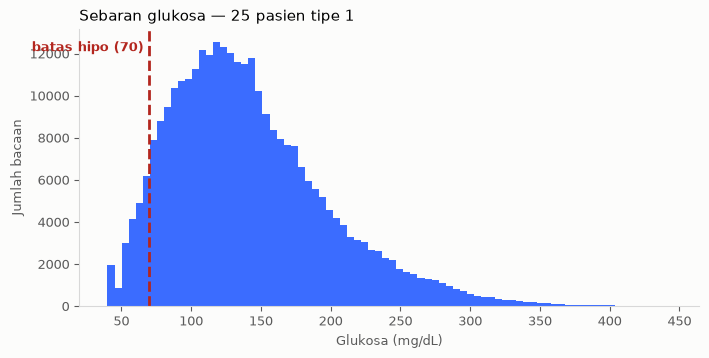

In [20]:

g = hupa['glucose'].dropna()
n_hipo = (g < HIPO).sum()
prev = n_hipo / len(g)
print(f'Bacaan glukosa   : {len(g):,}')
print(f'Hipoglikemia <70 : {n_hipo:,}  ({prev:.2%})')
print(f'Rata-rata        : {g.mean():.0f} mg/dL')
print(f'Rentang          : {g.min():.0f} - {g.max():.0f} mg/dL')
print()
print(f"=> Model yang SELALU menjawab 'aman' akan berakurasi {1-prev:.1%}")
print('   tanpa pernah menangkap satu kejadian pun.')

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(g, bins=80, color=BIRU)
ax.axvline(HIPO, color=MERAH, lw=2, ls='--')
ax.text(HIPO - 4, ax.get_ylim()[1]*0.92, 'batas hipo (70)', color=MERAH,
        ha='right', fontweight='bold', fontsize=9)
ax.set_title('Sebaran glukosa — 25 pasien tipe 1', loc='left')
ax.set_xlabel('Glukosa (mg/dL)'); ax.set_ylabel('Jumlah bacaan')
for s in ('top','right'): ax.spines[s].set_visible(False)
plt.show()


## 1.3 Seberapa berbeda detak jantung antar-orang?

**Pertanyaan 2 — ini yang paling menentukan rancangan.**
Kalau sebaran detak antar-orang saling tumpang tindih dan titik normalnya berbeda jauh,
maka **satu ambang untuk semua orang mustahil dibuat.**



In [21]:
per_pasien = hupa.groupby('pasien')['heart_rate'].agg(['mean','std','min','max']).round(1)
per_pasien = per_pasien.sort_values('mean')
print('Detak jantung rata-rata per pasien:')
print(f"  Terendah : {per_pasien['mean'].min():.1f} bpm")
print(f"  Tertinggi: {per_pasien['mean'].max():.1f} bpm")
print(f"  Selisih  : {per_pasien['mean'].max() - per_pasien['mean'].min():.1f} bpm")
per_pasien


Detak jantung rata-rata per pasien:
  Terendah : 62.7 bpm
  Tertinggi: 89.8 bpm
  Selisih  : 27.1 bpm


,mean,std,min,max
pasien,,,,
HUPA0022P,62.7,10.4,45.6,150.2
HUPA0006P,65.6,14.3,41.4,157.7
HUPA0002P,66.7,12.0,39.4,118.1
HUPA0023P,68.0,13.1,46.9,131.3
HUPA0015P,68.5,14.7,49.4,174.7
HUPA0007P,70.2,14.5,43.9,149.4
HUPA0019P,71.9,19.7,37.1,163.2
HUPA0011P,73.8,14.6,49.0,163.8
HUPA0024P,73.8,15.9,47.2,117.6


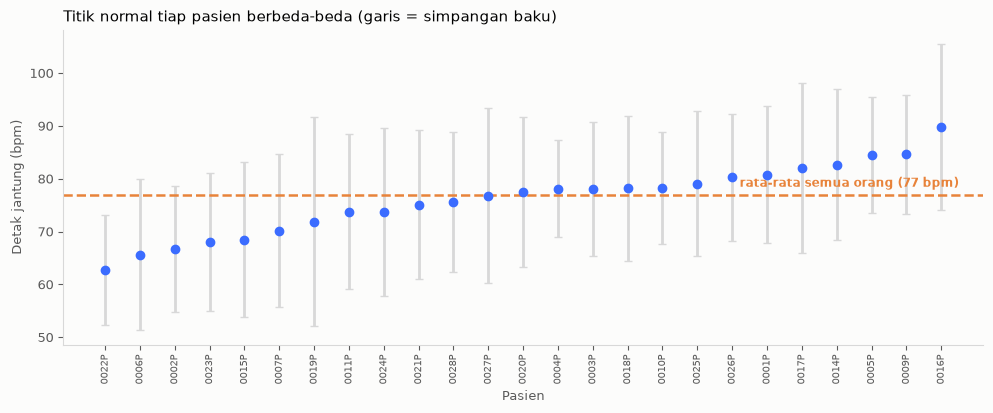

KESIMPULAN: satu ambang tetap untuk semua orang tidak mungkin —
nilai yang normal bagi satu pasien bisa berarti anomali bagi pasien lain.
Inilah dasar rancangan BASELINE PERSONAL.


In [22]:
fig, ax = plt.subplots(figsize=(10, 4.2))
urut = per_pasien.index
ax.errorbar(range(len(urut)), per_pasien['mean'], yerr=per_pasien['std'],
            fmt='o', color=BIRU, ecolor=GARIS, elinewidth=2, capsize=3, ms=6)
rerata = hupa['heart_rate'].mean()
ax.axhline(rerata, color=JINGGA, lw=1.8, ls='--')
ax.text(len(urut)-0.5, rerata+1.5, f'rata-rata semua orang ({rerata:.0f} bpm)',
        color=JINGGA, ha='right', fontweight='bold', fontsize=8.5)
ax.set_xticks(range(len(urut)))
ax.set_xticklabels([u.replace('HUPA','') for u in urut], rotation=90, fontsize=7)
ax.set_title('Titik normal tiap pasien berbeda-beda (garis = simpangan baku)', loc='left')
ax.set_ylabel('Detak jantung (bpm)'); ax.set_xlabel('Pasien')
for s in ('top','right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

print('KESIMPULAN: satu ambang tetap untuk semua orang tidak mungkin —')
print('nilai yang normal bagi satu pasien bisa berarti anomali bagi pasien lain.')
print('Inilah dasar rancangan BASELINE PERSONAL.')


## 1.4 Apakah detak jantung saja cukup?

**Pertanyaan 3.** Bandingkan sebaran detak saat hipoglikemia vs saat normal.
Kalau dua sebaran itu bertumpuk, detak jantung saja tak bisa memisahkan.


Saat hipoglikemia : 74.0 +/- 15.8 bpm  (n=20,377)
Saat normal       : 77.2 +/- 15.5 bpm  (n=289,015)
Selisih rata-rata : -3.2 bpm


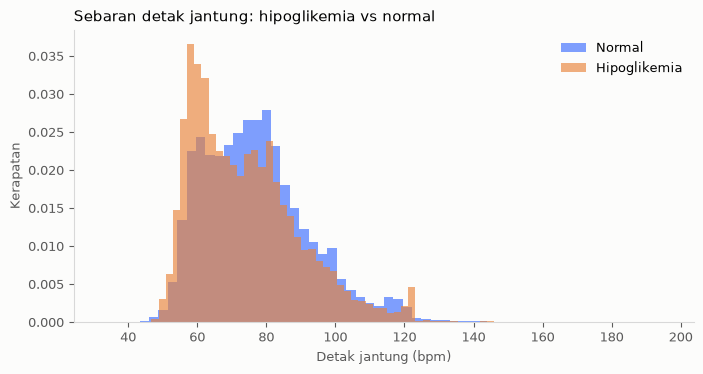


=> Kedua sebaran hampir bertumpuk sempurna. Detak jantung SAJA tidak
   memisahkan hipoglikemia dari kondisi normal. Ini menjelaskan mengapa
   14 model yang kami uji semuanya mentok di sekitar tebakan acak.


In [23]:
d = hupa.dropna(subset=['glucose','heart_rate'])
hr_hipo = d[d.glucose < HIPO]['heart_rate']
hr_norm = d[d.glucose >= HIPO]['heart_rate']

print(f'Saat hipoglikemia : {hr_hipo.mean():.1f} +/- {hr_hipo.std():.1f} bpm  (n={len(hr_hipo):,})')
print(f'Saat normal       : {hr_norm.mean():.1f} +/- {hr_norm.std():.1f} bpm  (n={len(hr_norm):,})')
print(f'Selisih rata-rata : {hr_hipo.mean() - hr_norm.mean():+.1f} bpm')

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(hr_norm, bins=60, density=True, alpha=0.65, color=BIRU, label='Normal')
ax.hist(hr_hipo, bins=60, density=True, alpha=0.65, color=JINGGA, label='Hipoglikemia')
ax.set_title('Sebaran detak jantung: hipoglikemia vs normal', loc='left')
ax.set_xlabel('Detak jantung (bpm)'); ax.set_ylabel('Kerapatan')
ax.legend(frameon=False)
for s in ('top','right'): ax.spines[s].set_visible(False)
plt.show()

print()
print('=> Kedua sebaran hampir bertumpuk sempurna. Detak jantung SAJA tidak')
print('   memisahkan hipoglikemia dari kondisi normal. Ini menjelaskan mengapa')
print('   14 model yang kami uji semuanya mentok di sekitar tebakan acak.')


## 1.5 Contoh rekaman satu pasien

Melihat bentuk datanya secara langsung — glukosa dan detak jantung berdampingan.


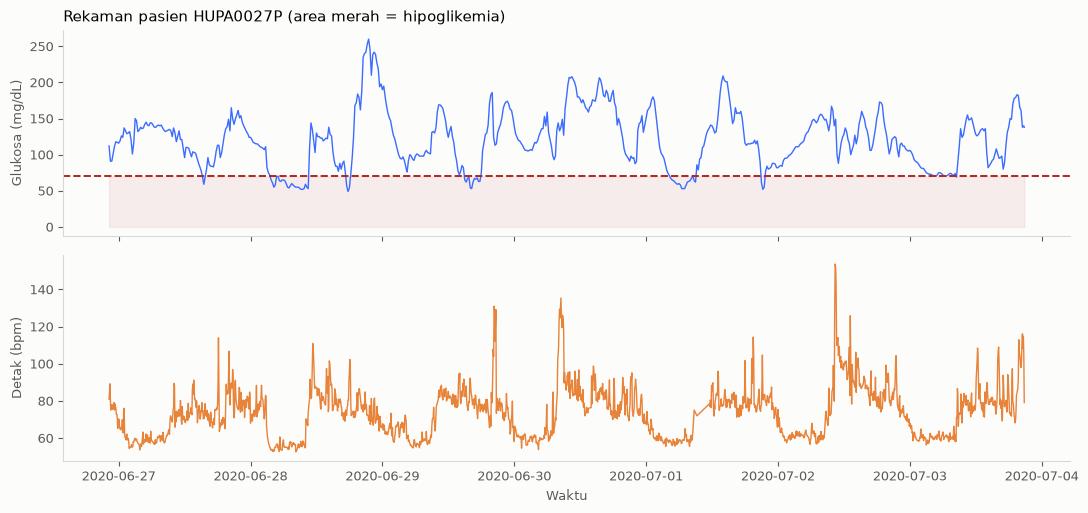

In [24]:
pilih = hupa.pasien.value_counts().index[0]
s = hupa[hupa.pasien == pilih].sort_values('time').head(2000)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
axes[0].plot(s.time, s.glucose, color=BIRU, lw=1)
axes[0].axhline(HIPO, color=MERAH, lw=1.4, ls='--')
axes[0].fill_between(s.time, 0, HIPO, color=MERAH, alpha=0.07)
axes[0].set_ylabel('Glukosa (mg/dL)')
axes[0].set_title(f'Rekaman pasien {pilih} (area merah = hipoglikemia)', loc='left')
axes[1].plot(s.time, s.heart_rate, color=JINGGA, lw=1)
axes[1].set_ylabel('Detak (bpm)'); axes[1].set_xlabel('Waktu')
for a in axes:
    for sp in ('top','right'): a.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()


## 1.6 Pola siang vs malam

Sasaran utama alat adalah hipoglikemia saat tidur. Apakah polanya memang berbeda?


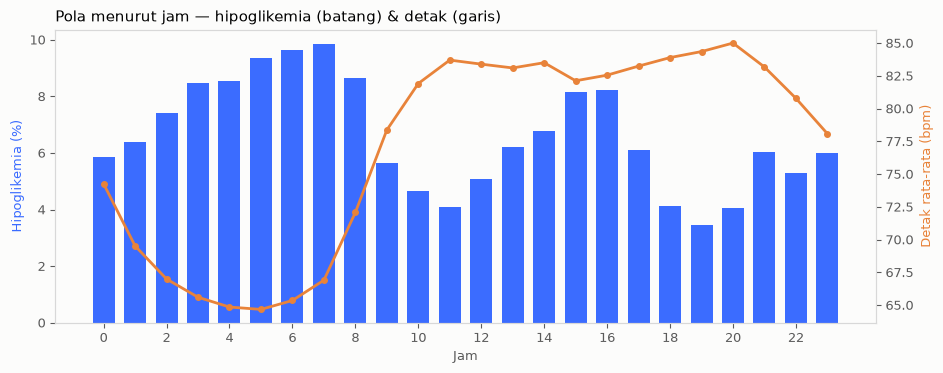

Hipoglikemia malam (23-06) : 7.70%
Hipoglikemia siang         : 6.03%
Detak rata-rata malam      : 68.7 bpm
Detak rata-rata siang      : 81.1 bpm

Detak jantung punya ritme harian -> patokan personal sebaiknya
dipisah siang/malam, bukan satu angka untuk sepanjang hari.


In [25]:
d = hupa.dropna(subset=['glucose','heart_rate']).copy()
d['jam'] = d.time.dt.hour
d['malam'] = d.jam.isin([23,0,1,2,3,4,5,6])

ring = d.groupby('jam').agg(
    hipo=('glucose', lambda x: (x < HIPO).mean()*100),
    detak=('heart_rate','mean')).round(2)

fig, ax1 = plt.subplots(figsize=(9.5, 3.8))
ax1.bar(ring.index, ring.hipo, color=BIRU, width=0.7)
ax1.set_xlabel('Jam'); ax1.set_ylabel('Hipoglikemia (%)', color=BIRU)
ax2 = ax1.twinx()
ax2.plot(ring.index, ring.detak, color=JINGGA, lw=2, marker='o', ms=4)
ax2.set_ylabel('Detak rata-rata (bpm)', color=JINGGA)
ax1.set_title('Pola menurut jam — hipoglikemia (batang) & detak (garis)', loc='left')
ax1.set_xticks(range(0,24,2))
plt.tight_layout(); plt.show()

print(f"Hipoglikemia malam (23-06) : {d[d.malam].glucose.lt(HIPO).mean():.2%}")
print(f"Hipoglikemia siang         : {d[~d.malam].glucose.lt(HIPO).mean():.2%}")
print(f"Detak rata-rata malam      : {d[d.malam].heart_rate.mean():.1f} bpm")
print(f"Detak rata-rata siang      : {d[~d.malam].heart_rate.mean():.1f} bpm")
print()
print('Detak jantung punya ritme harian -> patokan personal sebaiknya')
print('dipisah siang/malam, bukan satu angka untuk sepanjang hari.')


---
# BAGIAN 2 — BIG IDEAs Lab

Gelang Empatica E4. Berisi `IBI_*.csv` (jarak antar-detak) dan
`Dexcom_*.csv` (glukosa). Dipakai memvalidasi **ekstraksi PRV**.


In [26]:
ibi_files = sorted(glob.glob(os.path.join(DIR_BIG, 'IBI_*.csv')))
dex_files = sorted(glob.glob(os.path.join(DIR_BIG, 'Dexcom_*.csv')))
print(f'Berkas IBI    : {len(ibi_files)}')
print(f'Berkas Dexcom : {len(dex_files)}')

contoh = pd.read_csv(ibi_files[0])
print(f'Kolom IBI     : {list(contoh.columns)}')
contoh.head()


Berkas IBI    : 11
Berkas Dexcom : 16
Kolom IBI     : ['datetime', ' ibi']


,datetime,ibi
0,2020-02-13 15:33:22.059328,0.828163
1,2020-02-13 15:33:22.934368,0.875040
2,2020-02-13 15:34:21.593303,0.984420
3,2020-02-13 15:34:22.483969,0.890666
4,2020-02-13 15:34:23.421512,0.937543


## 2.1 Berapa banyak hipoglikemia di sini?

Ini yang menentukan apakah dataset ini bisa dipakai melatih **deteksi**.


In [27]:
semua_g = []
for f in dex_files:
    d = pd.read_csv(f)
    kol = [c for c in d.columns if 'Glucose' in c or 'glucose' in c]
    if not kol: continue
    v = pd.to_numeric(d[kol[0]].replace({'Low': 40, 'High': 400}), errors='coerce').dropna()
    semua_g.append(v)
gl = pd.concat(semua_g, ignore_index=True)

n_hipo = (gl < HIPO).sum()
print(f'Bacaan glukosa   : {len(gl):,}')
print(f'Hipoglikemia <70 : {n_hipo:,}  ({n_hipo/len(gl):.2%})')
print()
print('BANDINGKAN dengan HUPA-UCM yang 6-7%.')
print('=> Terlalu sedikit untuk melatih deteksi. Dataset ini hanya dipakai')
print('   memvalidasi apakah PIPELINE PRV kami menghasilkan angka yang wajar.')


Bacaan glukosa   : 36,962
Hipoglikemia <70 : 243  (0.66%)

BANDINGKAN dengan HUPA-UCM yang 6-7%.
=> Terlalu sedikit untuk melatih deteksi. Dataset ini hanya dipakai
   memvalidasi apakah PIPELINE PRV kami menghasilkan angka yang wajar.


## 2.2 Validasi ekstraksi PRV

RMSSD dihitung per jendela 2 menit, lalu dibandingkan dengan rujukan
orang dewasa sehat (**20–60 ms**). Kalau hasilnya masuk rentang wajar,
berarti kode pengolahan sinyal kami sehat.


In [16]:
IBI_MIN, IBI_MAX, MIN_DENYUT, JENDELA = 300, 2000, 20, 120

def rmssd(x):
    d = np.diff(x)
    return float(np.sqrt(np.mean(d*d))) if len(d) else np.nan

baris = []
for f in ibi_files:
    d = pd.read_csv(f); d.columns = [c.strip() for c in d.columns]
    ibi = pd.to_numeric(d['ibi'], errors='coerce') * 1000
    t = pd.to_datetime(d['datetime'], errors='coerce')
    ok = ibi.notna() & t.notna() & ibi.between(IBI_MIN, IBI_MAX)
    ibi, t = ibi[ok].to_numpy(), t[ok].reset_index(drop=True)
    if len(ibi) < MIN_DENYUT: continue
    detik = (t - t.iloc[0]).dt.total_seconds().to_numpy()
    w = (detik // JENDELA).astype(int)
    rs = [rmssd(ibi[w==k]) for k in np.unique(w) if (w==k).sum() >= MIN_DENYUT]
    hr = [60000/np.mean(ibi[w==k]) for k in np.unique(w) if (w==k).sum() >= MIN_DENYUT]
    if rs:
        baris.append({'subjek': os.path.basename(f)[4:-4],
                      'n_denyut': len(ibi), 'n_jendela': len(rs),
                      'RMSSD_med': np.median(rs), 'HR_med': np.median(hr)})
prv = pd.DataFrame(baris).round(1)
prv


,subjek,n_denyut,n_jendela,RMSSD_med,HR_med
0,001,266366,3024,67.7,61.6
1,002,474008,4296,50.7,80.7
2,003,166216,1857,53.8,71.7
3,004,201144,2083,60.2,70.9
4,005,274690,3139,57.7,68.2
5,006,163170,1897,62.5,73.6
6,007,375576,3994,46.5,66.9
7,008,313612,3272,51.4,68.0
8,009,223650,2448,27.9,64.4
9,010,233980,2608,45.7,58.8


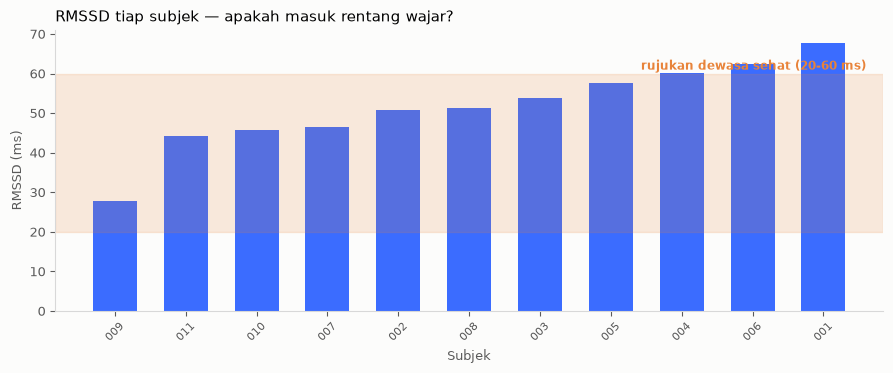

RMSSD median antar-subjek : 51.4 ms
Rentang                   : 27.9 - 67.7 ms
HR median                 : 59 - 81 bpm

=> Nilainya wajar secara fisiologis. PIPELINE PRV kami SEHAT.
   Yang belum teruji: apakah PRV mampu MEMBEDAKAN hipoglikemia.


In [17]:
fig, ax = plt.subplots(figsize=(9, 3.8))
p = prv.sort_values('RMSSD_med')
ax.bar(p.subjek, p.RMSSD_med, color=BIRU, width=0.62)
ax.axhspan(20, 60, color=JINGGA, alpha=0.16)
ax.text(len(p)-0.4, 61, 'rujukan dewasa sehat (20-60 ms)', color=JINGGA,
        ha='right', fontweight='bold', fontsize=8.5)
ax.set_title('RMSSD tiap subjek — apakah masuk rentang wajar?', loc='left')
ax.set_ylabel('RMSSD (ms)'); ax.set_xlabel('Subjek')
plt.xticks(rotation=45, fontsize=8)
for s in ('top','right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

print(f"RMSSD median antar-subjek : {prv.RMSSD_med.median():.1f} ms")
print(f"Rentang                   : {prv.RMSSD_med.min():.1f} - {prv.RMSSD_med.max():.1f} ms")
print(f"HR median                 : {prv.HR_med.min():.0f} - {prv.HR_med.max():.0f} bpm")
print()
print('=> Nilainya wajar secara fisiologis. PIPELINE PRV kami SEHAT.')
print('   Yang belum teruji: apakah PRV mampu MEMBEDAKAN hipoglikemia.')


---
# 📌 Kesimpulan Telaah

| Pertanyaan | Jawaban dari data |
|---|---|
| Seberapa jarang hipoglikemia? | HUPA ~6-7%, BIG IDEAs <1% → **akurasi tidak layak dipakai**, harus sensitivitas & spesifisitas |
| Seberapa berbeda antar-orang? | Detak rata-rata antar pasien berbeda puluhan bpm → **baseline personal wajib** |
| Cukupkah detak jantung saja? | Sebaran saat hipo & normal **bertumpuk** → **tidak cukup**, perlu PRV |
| Apakah pipeline PRV sehat? | RMSSD masuk rentang rujukan → **ya, sehat** |

**Yang belum terjawab dan memerlukan data primer:**
apakah PRV dari sensor kami sendiri mampu membedakan hipoglikemia.

*Dataset yang dapat menjawabnya: **PhysioCGM** (10 pasien tipe 1, PPG pergelangan + CGM).*
